### Libraries

On runAI, we use the following libraries on top of the pytorch image

In [ ]:
!pip install tqdm pandas numpy scikit-learn nltk bertopic sentence-transformers cuml accelerate jupyter ipywidgets

In [1]:
%load_ext autoreload
%autoreload 2
import os
from pathlib import Path
from tqdm import tqdm
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
import nltk
from nltk.corpus import stopwords

from sentence_transformers import SentenceTransformer
import torch
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer

try:
    from cuml.manifold import UMAP
    from cuml.cluster import HDBSCAN
except ImportError:
    from umap import UMAP
    from hdbscan import HDBSCAN

# Speech Data
They are fetched using the `paragraph_extraction.py` script which matches the Specch_ID with the corresponding metadata in the Neo4J database.

In [2]:
df = pd.read_csv("data/speeches_with_text.csv")

In [3]:
df

,Speech_ID,Discussion_ID,Partition_ID,name,role,language_of_text,TEXT_SPAN
0,100000,15837.0,15837.9,Schenker Silvia,NaN,DE,Ich werde beide Minderheiten gleichzeitig begr...
1,100007,15837.0,15837.1,Simoneschi-Cortesi Chiara,President,FR,Je vous annonce une très belle nouvelle: notre...
2,100009,15837.0,15837.1,Hassler Hansjörg,NaN,DE,Wir erachten diese vorgesehene Differenzierung...
3,100010,15837.0,15837.1,Carobbio Guscetti Marina,NaN,DE,Für die SP-Fraktion sind diese dringlichen Mas...
4,100011,15837.0,15837.1,Stahl Jürg,NaN,DE,Der Artikel 64 verkörpert das Alternativkonzep...
...,...,...,...,...,...,...,...
132753,99995,15837.0,15837.9,Goll Christine,NaN,DE,Wollen Sie tatsächlich noch mehr Kosten auf al...
132754,99996,15837.0,15837.9,Simoneschi-Cortesi Chiara,President,FR,Le groupe libéral-radical soutient la proposit...
132755,99997,15837.0,15837.9,Bortoluzzi Toni,NaN,DE,Die Kommission hat sich hier für eine Korrektu...
132756,99998,15837.0,15837.9,Weibel Thomas,NaN,DE,Vergleicht man die Beiträge von Langzeitpatien...


In [4]:
texts = df["TEXT_SPAN"].tolist()

The bills topics are instead manually defined here and come from the SwissDomainBERT2 model.

In [5]:
bills_topics = ['Civil Rights', 'Technology, Communication', 'International Affairs', 'Government Operations', 'Economy', 'Education, Research', 'Culture, Arts, Religion, Sport, Entertainment', 'Public Finances, Taxation', 'Agriculture', 'Social Welfare', 'Labor', 'Health', 'National Security, Armed Forces, Defense', 'Environment', 'Energy', '(Public) Transportation', 'Finances, Financial Sector', 'Spatial Planing, Civil Engineering', 'Migration', 'Parliamentary Procedure', 'Criminal Law']
print(f"Found {len(bills_topics)} unique topics: {bills_topics}")

Found 21 unique topics: ['Civil Rights', 'Technology, Communication', 'International Affairs', 'Government Operations', 'Economy', 'Education, Research', 'Culture, Arts, Religion, Sport, Entertainment', 'Public Finances, Taxation', 'Agriculture', 'Social Welfare', 'Labor', 'Health', 'National Security, Armed Forces, Defense', 'Environment', 'Energy', '(Public) Transportation', 'Finances, Financial Sector', 'Spatial Planing, Civil Engineering', 'Migration', 'Parliamentary Procedure', 'Criminal Law']


# Embeddings (Qwen3-0.6B)

Instantiate the Embedding model

In [6]:
# Load the embedding model
EMBEDDING_MODEL = "Qwen/Qwen3-Embedding-0.6B"
embedder = SentenceTransformer(
    EMBEDDING_MODEL,
    trust_remote_code=True,
    model_kwargs={
        "torch_dtype": torch.bfloat16,
        "attn_implementation": "sdpa",
    },
    processor_kwargs={"padding_side": "left"},
)

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Uncomment to compute again the Qwen embeddings over the paragraphs.

In [7]:
#embeddings = embedder.encode(
#   texts,
#   normalize_embeddings=True,
#   batch_size=4,
#   show_progress_bar=True,
#)

We store the precomputed embeddings to avoid recomputing them every time.

In [8]:
#np.save(f"speech_embeddings_{EMBEDDING_MODEL.split("/")[-1]}.npy", embeddings)

Load back pretrained embeddings and normalize to unit length for cosine similarity search.

In [9]:
# Load pre-computed embeddings
embeddings = np.load(f"speech_embeddings_{EMBEDDING_MODEL.split("/")[-1]}.npy")

# Normalize embeddings to unit length
embeddings = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)
embeddings.shape

(132758, 1024)

# BERTopic Model (UMAP + HDBSCAN)

Core part of the code, we need to define several hyperparameters for the dimensionality reduction, clustering and zero-shot assingment of the 21 topics (by means of minimum cosine similarity).

The `ZEROSHOT_MIN_SIMILARITY` is a hyperparameter that can be tuned to assign in a zero-shot fashion one of the 21 Bills Topics to the extracted speech paragraphs.

For UMAP, we need to define the number of dimensions to reduce to, the number of neighbors to consider and the distance metric.

For HDBSCAN, we have several hyperparameters to tune, among them the minimum cluster size, the minimum number of samples in a cluster, the cluster selection method (EOM or Leaf - depending whether we want to start from a bigger cluster and then split it or to start from smaller clusters and then merge them) and the cluster selection epsilon (which is a distance threshold to split clusters that are too far apart).

There are some rules of thumb to tune these hyperparameters, but in general it is a good idea to try different combinations and see which one gives the best results in terms of coherence and interpretability of the topics.

>The more interpretable the topics are, the better the LLM refinement will be, which is crucial for the downstream tasks of stance detection.

In [10]:
# Hyperparameters for BERTopic
RANDOM_SEED = 42

# UMAP
N_NEIGHBORS = 20
N_COMPONENTS = 5
METRIC = "cosine"

# HDBSCAN
MIN_CLUSTER_SIZE = 150
#MIN_SAMPLES = 10
CLUSTER_SELECTION_METHOD = "leaf"  # "eom" (excess of mass) or "leaf"
#CLUSTER_SELECTION_EPSILON = 0.1

# Zero-Shot topic
ZEROSHOT_MIN_SIMILARITY = 0.75  # Min cos similarity between speech embedding and predefined topic embedding to assign the topic to the speech

We use NLTK to load common stopwords in German, French and Italian to remove them from the extracted topics, which helps the CountVectorizer to better capture the important words in the topics and to improve the coherence of the topics.

The cTF-IDF is a variant of the TF-IDF that is computed for multiple classes by joining all documents per class. Each class is converted to a single document instead of set of documents. The frequency of each word x is extracted for each class c and is l1 normalized. This constitutes the term frequency. Then, the term frequency is multiplied with IDF which is the logarithm of 1 plus the average number of words per class A divided by the frequency of word x across all classes.

TF-IDF is used to extract the most important words for each topic, which are then used to "represent" the cluster by means of these keywords.

In [11]:
# Download stopwords for German, French, and Italian
nltk.download("stopwords")

# Combine stopwords from German, French, and Italian
stop_words_multi = (
    stopwords.words("german") + stopwords.words("french") + stopwords.words("italian")
)

# UMAP for dimensionality reduction
umap_model = UMAP(
    n_neighbors=N_NEIGHBORS,
    n_components=N_COMPONENTS,
    metric=METRIC,
    random_state=RANDOM_SEED,
)

# HDBSCAN for clustering
hdbscan_model = HDBSCAN(
    min_cluster_size=MIN_CLUSTER_SIZE,
    #min_samples=MIN_SAMPLES,
    cluster_selection_method=CLUSTER_SELECTION_METHOD,
    #cluster_selection_epsilon=CLUSTER_SELECTION_EPSILON,
    prediction_data=True,
)

# CountVectorizer with custom stop words (German, French, Italian)
vectorizer_model = CountVectorizer(
    stop_words=stop_words_multi,
)
# TF-IDF transformer that reduces the importance of frequent words across topics
ctfidf_model = ClassTfidfTransformer(reduce_frequent_words=True)

# Initialize BERTopic with the specified models and parameters
topic_model = BERTopic(
    embedding_model=embedder,
    umap_model=umap_model,
    hdbscan_model=hdbscan_model,
    vectorizer_model=vectorizer_model,
    ctfidf_model=ctfidf_model,
    verbose=True,
    zeroshot_topic_list=bills_topics,
    zeroshot_min_similarity=ZEROSHOT_MIN_SIMILARITY,
)

[2026-06-05 13:51:30.357] [CUML] [info] build_algo set to brute_force_knn because random_state is given


[nltk_data] Downloading package stopwords to /myhome/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


If we have already saved the model locally, we can load it back otherswise we fit the model and save it for future use.

In [12]:
topics, probs = topic_model.fit_transform(texts, embeddings=embeddings)

2026-06-05 13:51:30,547 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-06-05 13:51:34,756 - BERTopic - Dimensionality - Completed ✓
2026-06-05 13:51:34,763 - BERTopic - Zeroshot Step 1 - Finding documents that could be assigned to either one of the zero-shot topics
2026-06-05 13:51:36,712 - BERTopic - Zeroshot Step 1 - Completed ✓
2026-06-05 13:51:39,004 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-06-05 13:51:43,453 - BERTopic - Cluster - Completed ✓
2026-06-05 13:51:43,481 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-06-05 13:52:17,346 - BERTopic - Representation - Completed ✓


We inspect the resulting topics

In [13]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,88976,-1_cette_fédéral_conseil_commission,"[cette, fédéral, conseil, commission, schweiz,...",[Il vient d'être question à l'instant de l'ini...
1,0,4533,0_ordnungsantrag_antrag_kommission_nationalrat,"[ordnungsantrag, antrag, kommission, nationalr...","[Kollege Jositsch, Sie haben die rhetorischen ..."
2,1,1962,1_prämien_versicherer_versicherten_kvg,"[prämien, versicherer, versicherten, kvg, kran...",[Am 24. März 2000 verabschiedete das Parlament...
3,2,1755,2_verkehr_strasse_sbb_schiene,"[verkehr, strasse, sbb, schiene, bahn, güterve...",[Im Namen einer starken Minderheit stelle ich ...
4,3,1738,3_armee_rüstungsprogramm_zivildienst_beschaffung,"[armee, rüstungsprogramm, zivildienst, beschaf...","[Gestatten Sie mir vielleicht, vorerst noch ei..."
...,...,...,...,...,...
68,67,182,67_kriegsmaterial_waffen_rüstungsindustrie_kri...,"[kriegsmaterial, waffen, rüstungsindustrie, kr...",[Ich möchte mich bei der vorberatenden Kommiss...
69,68,172,68_terrorismus_kaida_terroristischen_terrorist...,"[terrorismus, kaida, terroristischen, terroris...",[Es geht bei diesem Geschäft und auch beim näc...
70,69,169,69_groupe_soutiennent_pvl_soutient,"[groupe, soutiennent, pvl, soutient, radical, ...","[Le groupe socialiste soutient la minorité, al..."
71,70,159,70_digitalisierung_digitale_open_digitalen,"[digitalisierung, digitale, open, digitalen, g...",[Der Bundesrat empfiehlt die Annahme der Motio...


In [14]:
#topic_model.visualize_topics()

In [15]:
#top_n = 20
#topic_model.visualize_heatmap(top_n_topics=top_n, title=f"Top {top_n} Topics Heatmap")

# Topic Representation Refinement (via SDSC Qwen)

Here you will need to pass your API KEY for the SDSC Qwen.

In [18]:
import json

with open("/myhome/.config/io.datasette.llm/keys.json", "r") as f:
    keys = json.load(f)

API_KEY = keys["sdsc-key"]

In [19]:
DEFAULT_CHAT_PROMPT="""You will extract a short topic label from given documents and keywords.

Your task:
1. Provide a concise and descriptive label that represents the cluster.

Here an example of topic you created before:

# Example 1
Sample texts from this topic:
- Les primes d'assurance maladie augmentent chaque année...
- Wir müssen die Gesundheitskosten dämpfen...
Keywords: primes, Krankenkasse, santé, Gesundheitskosten, insurance
topic: Healthcare costs and insurance premiums

# Your current task
Sample texts from this topic:
[DOCUMENTS]

Keywords: [KEYWORDS]

Based on the information above, extract a short topic label in the following format:
topic: <topic_label>
"""

In [30]:
import requests
from scripts.const import DEFAULT_SYSTEM_PROMPT


def extract_topic_label(
    system_prompt: str = DEFAULT_SYSTEM_PROMPT,
    chat_prompt: str = DEFAULT_CHAT_PROMPT,
    temperature: float = 0.7,
    top_p: float = 0.8,
    top_k: int = 20,
    max_tokens: int = 256,
    presence_penalty: float = 1.5,
    enable_thinking: bool = False,
    endpoint: str = "https://vllm-gateway-runai-sharedllm-ralf.inference.compute.datascience.ch/v1/chat/completions",
    model: str = "Qwen/Qwen3.6-35B-A3B-FP8",
):
    r = requests.post(
        endpoint,
        headers={
            "Content-Type": "application/json",
            "Authorization": f"Bearer {API_KEY}",
        },
        json={
            "model": model,
            "messages": [
                {"role": "system", "content": system_prompt},
                {"role": "user", "content": chat_prompt},
            ],
            "temperature": temperature,
            "top_p": top_p,
            "top_k": top_k,
            "max_tokens": max_tokens,
            "presence_penalty": presence_penalty,
            "chat_template_kwargs": {"enable_thinking": enable_thinking},
        },
    )

    if r.ok:
        response = r.json()
        clean_response = response["choices"][0]["message"]["content"].strip()
        topic = clean_response.replace("topic:", "").strip()
        return topic
    print(f"Error: {r.status_code} - {r.text}")
    return None

In [31]:
from bertopic.representation._base import BaseRepresentation

class QwenTopic(BaseRepresentation):
    def __init__(
        self,
        bills_topics: list[str] = bills_topics,
        prompt=DEFAULT_CHAT_PROMPT,
        system_prompt=DEFAULT_SYSTEM_PROMPT,
        nr_docs: int = 10,
        nr_samples: int = 1000,
        temperature: float = 0.7,
        top_p: float = 0.8,
        top_k: int = 20,
        max_tokens: int = 256,
        presence_penalty: float = 1.5,
        enable_thinking: bool = False,
        diversity: float | None = None,
    ):
        self.bills_topics = bills_topics
        self.prompt = prompt
        self.system_prompt = system_prompt
        self.nr_docs = nr_docs
        self.nr_samples = nr_samples
        self.temperature = temperature
        self.top_p = top_p
        self.top_k = top_k
        self.max_tokens = max_tokens
        self.presence_penalty = presence_penalty
        self.enable_thinking = enable_thinking
        self.diversity = diversity

        self.prompts_ = []

    def extract_topics(self, topic_model, documents, c_tf_idf, topics):
        repr_docs_mappings, _, _, _ = topic_model._extract_representative_docs(
            c_tf_idf, documents, topics, self.nr_samples, self.nr_docs, self.diversity
        )

        updated_topics = {}
        for topic, docs in tqdm(
            repr_docs_mappings.items(), desc="Extracting topics with Qwen"
        ):
            prompt = self._create_prompt(docs, topic, topics)
            self.prompts_.append(prompt)

            label = extract_topic_label(
                chat_prompt=prompt,
                max_tokens=self.max_tokens,
                enable_thinking=self.enable_thinking,
            )
            updated_topics[topic] = [(label, 1)]

        return updated_topics

    def _create_prompt(self, docs, topic, topics):
        keywords = next(zip(*topics[topic]))

        prompt = self.prompt
        if "[BILLS_TOPICS]" in prompt:
            prompt = prompt.replace("[BILLS_TOPICS]", ", ".join(self.bills_topics))
        if "[KEYWORDS]" in prompt:
            prompt = prompt.replace("[KEYWORDS]", ", ".join(keywords))
        if "[DOCUMENTS]" in prompt:
            prompt = self._replace_documents(prompt, docs)

        return prompt

    @staticmethod
    def _replace_documents(prompt, docs):
        to_replace = ""
        for doc in docs:
            to_replace += f"- {doc}\n"
        prompt = prompt.replace("[DOCUMENTS]", to_replace)
        return prompt

    def get_prompts(self):
        """Returns the prompts used for topic extraction."""
        return self.prompts_

In [32]:
# Update topics with the new representation model based on Qwen
topic_model.update_topics(
    texts,
    representation_model=QwenTopic(
        nr_docs=10,
        nr_samples=1000,
        temperature=0.0,
        max_tokens=64,
        enable_thinking=False,
    ),
)

Extracting topics with Qwen: 100% 73/73 [07:22<00:00,  6.06s/it]


In [34]:
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,-1,88976,"-1_Swiss federal budget, healthcare financing,...","[Swiss federal budget, healthcare financing, a...",[Il vient d'être question à l'instant de l'ini...
1,0,4533,0_Parliamentary legislative procedures and com...,[Parliamentary legislative procedures and comm...,"[Kollege Jositsch, Sie haben die rhetorischen ..."
2,1,1962,1_Swiss health insurance cost containment and ...,[Swiss health insurance cost containment and r...,[Am 24. März 2000 verabschiedete das Parlament...
3,2,1755,2_Swiss transport infrastructure financing and...,[Swiss transport infrastructure financing and ...,[Im Namen einer starken Minderheit stelle ich ...
4,3,1738,3_Swiss Army Reform and Defense Policy,[Swiss Army Reform and Defense Policy],"[Gestatten Sie mir vielleicht, vorerst noch ei..."
...,...,...,...,...,...
68,67,182,67_Swiss arms export regulations and initiatives,[Swiss arms export regulations and initiatives],[Ich möchte mich bei der vorberatenden Kommiss...
69,68,172,68_Counter-terrorism legislation and preventiv...,[Counter-terrorism legislation and preventive ...,[Es geht bei diesem Geschäft und auch beim näc...
70,69,169,69_Political party voting records,[Political party voting records],"[Le groupe socialiste soutient la minorité, al..."
71,70,159,70_Digitalization of public administration and...,[Digitalization of public administration and e...,[Der Bundesrat empfiehlt die Annahme der Motio...


At the end we save the document topics, map back to the original dataframe and save the resulting dataframe with the new topic assignments.

In [35]:
doc_topics = topic_model.get_document_info(texts)
doc_topics.to_csv("bertopic_document_topics.csv", index=False)
doc_topics

,Document,Topic,Name,Representation,Representative_Docs,Top_n_words,Probability,Representative_document
0,Ich werde beide Minderheiten gleichzeitig begr...,1,1_Swiss health insurance cost containment and ...,[Swiss health insurance cost containment and r...,[Am 24. März 2000 verabschiedete das Parlament...,Swiss health insurance cost containment and re...,0.888548,False
1,Je vous annonce une très belle nouvelle: notre...,-1,"-1_Swiss federal budget, healthcare financing,...","[Swiss federal budget, healthcare financing, a...",[Il vient d'être question à l'instant de l'ini...,"Swiss federal budget, healthcare financing, an...",0.000000,False
2,Wir erachten diese vorgesehene Differenzierung...,1,1_Swiss health insurance cost containment and ...,[Swiss health insurance cost containment and r...,[Am 24. März 2000 verabschiedete das Parlament...,Swiss health insurance cost containment and re...,0.988142,False
3,Für die SP-Fraktion sind diese dringlichen Mas...,1,1_Swiss health insurance cost containment and ...,[Swiss health insurance cost containment and r...,[Am 24. März 2000 verabschiedete das Parlament...,Swiss health insurance cost containment and re...,0.902921,False
4,Der Artikel 64 verkörpert das Alternativkonzep...,1,1_Swiss health insurance cost containment and ...,[Swiss health insurance cost containment and r...,[Am 24. März 2000 verabschiedete das Parlament...,Swiss health insurance cost containment and re...,0.970600,False
...,...,...,...,...,...,...,...,...
132753,Wollen Sie tatsächlich noch mehr Kosten auf al...,1,1_Swiss health insurance cost containment and ...,[Swiss health insurance cost containment and r...,[Am 24. März 2000 verabschiedete das Parlament...,Swiss health insurance cost containment and re...,0.972482,False
132754,Le groupe libéral-radical soutient la proposit...,-1,"-1_Swiss federal budget, healthcare financing,...","[Swiss federal budget, healthcare financing, a...",[Il vient d'être question à l'instant de l'ini...,"Swiss federal budget, healthcare financing, an...",0.000000,False
132755,Die Kommission hat sich hier für eine Korrektu...,1,1_Swiss health insurance cost containment and ...,[Swiss health insurance cost containment and r...,[Am 24. März 2000 verabschiedete das Parlament...,Swiss health insurance cost containment and re...,0.959400,False
132756,Vergleicht man die Beiträge von Langzeitpatien...,1,1_Swiss health insurance cost containment and ...,[Swiss health insurance cost containment and r...,[Am 24. März 2000 verabschiedete das Parlament...,Swiss health insurance cost containment and re...,0.845772,False


In [42]:
full_df = pd.concat([df, doc_topics], axis=1)
full_df = full_df.drop(columns=["Document"])
full_df.to_csv("speeches_with_topics.csv", index=False)

<Axes: ylabel='Representation'>

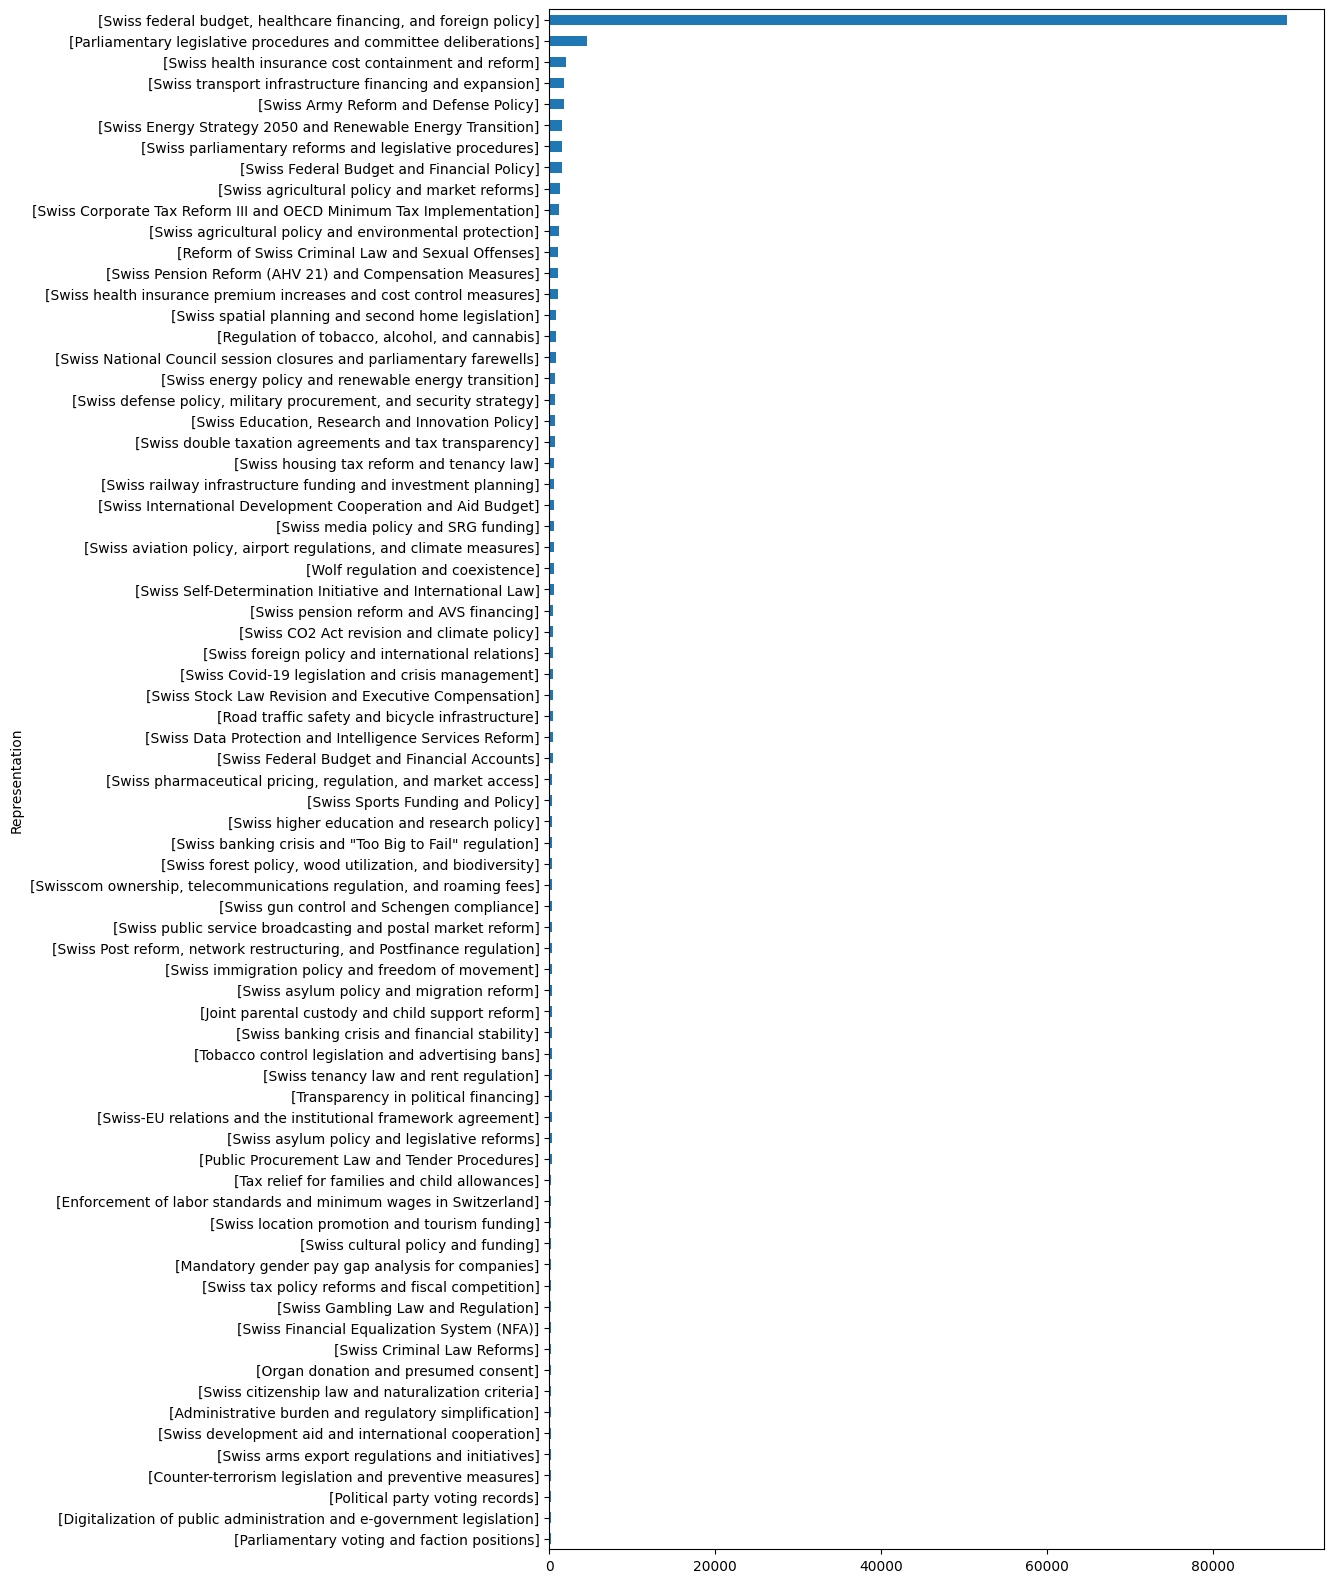

In [65]:
full_df['Representation'].value_counts(sort=True, ascending=True).plot(kind='barh', figsize=(10,20))